# LiF(e) formation energy: 1/n → 0 extrapolation

Data: `runs/e0-fit/tau{60,240}/n*/results/merged.json` (fixed-τ thermodynamic estimator, rank-800/f32 tables). The τ240 ladder also takes the 20³ point from `runs/guards/n20-tau240` (same config as `lif-slotmap`).

Fit model (weighted least squares, weights $1/\sigma_i^2$):

$$E_0(u) = E_\infty + C\,u + D\,u^2 + \dots,\qquad u = 1/n .$$

The leading $u$ term is the Γ-cell of the polar $1/q^2$ weight missing from the discrete sum $\frac{1}{N_q}\sum_{q\neq\Gamma}$. Higher powers are not controlled by a known expansion, so the spread over fit models and windows is quoted as a systematic. When $\chi^2_\mathrm{red} > 1$, parameter errors are scaled by $\sqrt{\chi^2_\mathrm{red}}$.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

FEP_INF = -0.408          # Luo–Park–Bernardi 2025, Table 1 (no AHC correction)
EXTRA = {240: {20: Path("../runs/guards/n20-tau240/results/merged.json")}}

def ladder(tau):
    files = {int(p.parts[-3][1:]): p for p in Path(f"../runs/e0-fit/tau{tau}").glob("n*/results/merged.json")}
    files.update(EXTRA.get(tau, {}))
    n = np.array(sorted(files))
    rep = [json.load(open(files[k]))["e0_thermo"] for k in n]
    return n, np.array([r["mean"] for r in rep]), np.array([r["stderr"] for r in rep])

L = {tau: ladder(tau) for tau in (60, 240)}
for tau, (n, E, s) in L.items():
    print(f"τ{tau}: " + "  ".join(f"n{k}: {e:+.5f}({1e5*x:.0f})" for k, e, x in zip(n, E, s)))

τ60: n20: -0.24976(9)  n32: -0.30389(11)  n40: -0.32301(11)  n50: -0.33829(11)  n60: -0.34903(12)  n80: -0.36198(13)  n100: -0.37014(14)  n120: -0.37548(15)
τ240: n20: -0.25065(30)  n40: -0.32550(21)  n60: -0.35154(24)  n80: -0.36530(28)  n100: -0.37368(34)  n120: -0.37828(34)


In [2]:
def fit(n, E, s, deg, sel):
    '''Weighted polynomial fit in u = 1/n over the points `sel`; returns E∞, its error, χ²_red, coeffs.'''
    u = 1 / n[sel]
    c, cov = np.polyfit(u, E[sel], deg, w=1 / s[sel], cov="unscaled")
    dof = sel.sum() - deg - 1
    chi2 = np.sum(((np.polyval(c, u) - E[sel]) / s[sel])**2) / dof if dof > 0 else np.nan
    err = np.sqrt(cov[-1, -1]) * (np.sqrt(chi2) if chi2 > 1 else 1.0)
    return c[-1], err, chi2, c

rows = []
for tau, (n, E, s) in L.items():
    for deg in (1, 2, 3):
        for nmin in sorted(set(n)):
            sel = n >= nmin
            if sel.sum() < deg + 2:          # need ≥ 1 dof
                continue
            einf, err, chi2, _ = fit(n, E, s, deg, sel)
            rows.append(dict(tau=tau, deg=deg, nmin=nmin, npts=int(sel.sum()), einf=einf, err=err, chi2=chi2))
    # FEP-DMC protocol: linear through the three largest grids.
    sel = n >= np.sort(n)[-3]
    einf, err, chi2, _ = fit(n, E, s, 1, sel)
    rows.append(dict(tau=tau, deg="1 (FEP: 3 largest)", nmin=int(n[sel].min()), npts=3, einf=einf, err=err, chi2=chi2))

print(f"{'τ':>4} {'deg':>20} {'n≥':>4} {'pts':>3} {'E∞ [eV]':>10} {'±':>8} {'χ²/dof':>7}")
for r in rows:
    print(f"{r['tau']:>4} {str(r['deg']):>20} {r['nmin']:>4} {r['npts']:>3} {r['einf']:+10.4f} {r['err']:8.4f} {r['chi2']:7.2f}")

   τ                  deg   n≥ pts    E∞ [eV]        ±  χ²/dof
  60                    1   20   8    -0.3991   0.0008   89.00
  60                    1   32   7    -0.4011   0.0003    6.47
  60                    1   40   6    -0.4015   0.0003    3.29
  60                    1   50   5    -0.4019   0.0002    1.09
  60                    1   60   4    -0.4018   0.0003    1.53
  60                    1   80   3    -0.4025   0.0005    0.12
  60                    2   20   8    -0.4030   0.0002    1.07
  60                    2   32   7    -0.4027   0.0003    1.10
  60                    2   40   6    -0.4029   0.0006    1.38
  60                    2   50   5    -0.4022   0.0010    1.56
  60                    2   60   4    -0.4040   0.0014    0.50
  60                    3   20   8    -0.4026   0.0005    1.14
  60                    3   32   7    -0.4030   0.0012    1.43
  60                    3   40   6    -0.4021   0.0026    1.96
  60                    3   50   5    -0.4071   0.0037 

## Plot: both ladders with error bars and the quadratic fits

The shaded bands are the $1\sigma$ confidence bands of the weighted quadratic fits over all rungs, propagated from the fit covariance (scaled by $\sqrt{\chi^2_\mathrm{red}}$ when above 1).

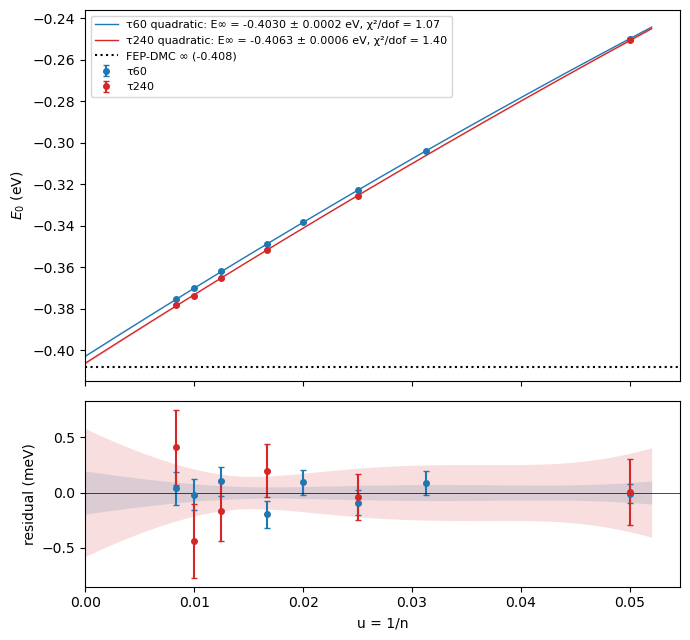

In [3]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(7, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
us = np.linspace(0, 0.052, 200)
for tau, color in ((60, "C0"), (240, "C3")):
    n, E, s = L[tau]
    u = 1 / n
    c, cov = np.polyfit(u, E, 2, w=1 / s, cov="unscaled")
    chi2 = np.sum(((np.polyval(c, u) - E) / s)**2) / (len(n) - 3)
    cov = cov * max(chi2, 1.0)
    V = np.vander(us, 3)                        # columns u², u, 1 — matches polyfit order
    band = np.sqrt(np.einsum("ij,jk,ik->i", V, cov, V))
    ax.errorbar(u, E, s, fmt="o", color=color, ms=4, capsize=2, label=f"τ{tau}")
    ax.plot(us, V @ c, "-", color=color, lw=1, label=f"τ{tau} quadratic: E∞ = {c[-1]:+.4f} ± {band[0]:.4f} eV, χ²/dof = {chi2:.2f}")
    ax.fill_between(us, V @ c - band, V @ c + band, color=color, alpha=0.2, lw=0)
    # Residuals in meV: the only place the sub-meV error bars are visible.
    axr.errorbar(u, 1e3 * (E - np.polyval(c, u)), 1e3 * s, fmt="o", color=color, ms=4, capsize=2)
    axr.fill_between(us, -1e3 * band, 1e3 * band, color=color, alpha=0.15, lw=0)
ax.axhline(FEP_INF, color="k", ls=":", label=f"FEP-DMC ∞ ({FEP_INF})")
ax.set_ylabel(r"$E_0$ (eV)"); ax.legend(fontsize=8)
axr.axhline(0, color="k", lw=0.5)
axr.set_xlabel("u = 1/n"); axr.set_ylabel("residual (meV)"); axr.set_xlim(left=0)
plt.tight_layout(); plt.savefig("ladder.png", dpi=150); plt.show()

## τ shift and the combined estimate

The τ240 − τ60 shift at matched n is flat for $n\ge40$, so the better-conditioned τ60 ladder (more rungs, down to 20³) can be carried to τ240 by adding the mean shift. This is an independent route to $E_\infty(\tau240)$ and cross-checks the direct τ240 fit.

In [4]:
n60, E60, s60 = L[60]; n240, E240, s240 = L[240]
common = sorted(set(n60) & set(n240))
d = np.array([E240[n240 == k][0] - E60[n60 == k][0] for k in common])
ds = np.array([np.hypot(s240[n240 == k][0], s60[n60 == k][0]) for k in common])
for k, x, e in zip(common, d, ds):
    print(f"n{k}: τ240 − τ60 = {1e3*x:+.2f} ± {1e3*e:.2f} meV")
m = np.array(common) >= 40
w = 1 / ds[m]**2
shift = np.sum(w * d[m]) / w.sum(); shift_err = 1 / np.sqrt(w.sum())
chi2 = np.sum(((d[m] - shift) / ds[m])**2) / (m.sum() - 1)
print(f"mean shift (n ≥ 40): {1e3*shift:+.2f} ± {1e3*shift_err:.2f} meV, χ²/dof = {chi2:.2f}")

e60, e60_err, _, _ = fit(n60, E60, s60, 2, n60 >= 20)
route_b = e60 + shift
print(f"τ60 quadratic (all rungs) + shift: E∞(τ240) = {route_b:+.4f} ± {np.hypot(e60_err, shift_err):.4f} eV")

n20: τ240 − τ60 = -0.88 ± 0.31 meV
n40: τ240 − τ60 = -2.49 ± 0.24 meV
n60: τ240 − τ60 = -2.51 ± 0.27 meV
n80: τ240 − τ60 = -3.32 ± 0.30 meV
n100: τ240 − τ60 = -3.54 ± 0.36 meV
n120: τ240 − τ60 = -2.80 ± 0.37 meV
mean shift (n ≥ 40): -2.83 ± 0.13 meV, χ²/dof = 2.46
τ60 quadratic (all rungs) + shift: E∞(τ240) = -0.4058 ± 0.0002 eV


## Error budget

| Contribution | Source |
|---|---|
| statistical | fit covariance of the quoted fit |
| fit model / window | half-range of $E_\infty$ over the acceptable τ240 fits ($\chi^2_\mathrm{red}\le2.2$, own error $\le2$ meV) plus the shift route |
| compression | $\Delta_\mathrm{rank}(800) = E_0(800) - E_0(1600) = +0.5 \pm 0.3$ meV at 20³ (`runs/guards/n20-r1600`): rank 800 sits slightly *above* the uncompressed value, so a correction of about $-0.5$ meV |
| τ | τ480 − τ240 at n = 120 (`runs/guards/n120-tau480`, config `lif-slotmap-tau480`); read automatically once merged |

Not included, and not a DiagMC error: remote bands (Allen–Heine–Cardona) and Debye–Waller, which move the physical value to about −0.538 eV in FEP-DMC.

In [5]:
# Acceptable: χ²_red ≤ 2.2 and an own statistical error ≤ 2 meV (an under-determined fit, e.g. cubic on
# 5 points with a 6 meV error, is uninformative rather than a competing model).
ok = [r for r in rows if r["tau"] == 240 and r["chi2"] <= 2.2 and r["err"] <= 0.002 and isinstance(r["deg"], int)]
vals = np.array([r["einf"] for r in ok] + [route_b])
quoted = next(r for r in rows if r["tau"] == 240 and r["deg"] == 2 and r["nmin"] == 20)
n20r = json.load(open("../runs/guards/n20-r1600/results/merged.json"))["e0_thermo"]
d_rank = E60[n60 == 20][0] - n20r["mean"]; d_rank_err = np.hypot(s60[n60 == 20][0], n20r["stderr"])
sys_fit = (vals.max() - vals.min()) / 2
print(f"quoted fit: τ240 quadratic, all rungs: E∞ = {quoted['einf']:+.4f}")
print(f"  statistical     ± {quoted['err']:.4f} eV")
print(f"  fit model       ± {sys_fit:.4f} eV   (half-range over {len(vals)} acceptable fits: {vals.min():+.4f} … {vals.max():+.4f})")
print(f"  Δ_rank(800)     {1e3*d_rank:+.1f} ± {1e3*d_rank_err:.1f} meV (at 20³; not applied)")
tau480 = Path("../runs/guards/n120-tau480/results/merged.json")
if tau480.exists():
    g = json.load(open(tau480))["e0_thermo"]
    d_tau = g["mean"] - E240[n240 == 120][0]; d_tau_err = np.hypot(g["stderr"], s240[n240 == 120][0])
    print(f"  τ480 − τ240     {1e3*d_tau:+.1f} ± {1e3*d_tau_err:.1f} meV (at 120³; if significant, τ240 is not converged)")
else:
    print(f"  τ (τ480 guard)  pending: {tau480} not there yet")
tot = np.hypot(quoted["err"], sys_fit)
print(f"E∞(LiF e) = {quoted['einf']:+.4f} ± {quoted['err']:.4f} (stat) ± {sys_fit:.4f} (model) eV")
print(f"E∞(LiF e) = {quoted['einf']:+.4f} ± {tot:.4f} eV   vs FEP-DMC {FEP_INF}: {1e3*(quoted['einf']-FEP_INF):+.1f} meV")

quoted fit: τ240 quadratic, all rungs: E∞ = -0.4063
  statistical     ± 0.0006 eV
  fit model       ± 0.0008 eV   (half-range over 6 acceptable fits: -0.4064 … -0.4048)
  Δ_rank(800)     +0.5 ± 0.3 meV (at 20³; not applied)
  τ (τ480 guard)  pending: ../runs/guards/n120-tau480/results/merged.json not there yet
E∞(LiF e) = -0.4063 ± 0.0006 (stat) ± 0.0008 (model) eV
E∞(LiF e) = -0.4063 ± 0.0010 eV   vs FEP-DMC -0.408: +1.7 meV


## Free-τ vs fixed-τ at 40³

`runs/guards/n40-free-tau240` (config `lif-slotmap-free`) samples the external time τ ∈ (0, 240] and bins the same local energy $E_\mathrm{loc}$ in 10 eV⁻¹ bins. The per-bin average is the conditional expectation at that τ, so it must reproduce the fixed-τ points: τ60 (`e0-fit/tau60/n40`, the average of the two bins meeting at 60) and τ240 (`e0-fit/tau240/n40`, last bin, centre 235). The whole curve shows how $E(\tau)$ approaches $E_0$. A single-exponential fit $E(\tau) = E_0 + A e^{-\Delta\tau}$ gives the gap Δ controlling τ convergence: Δ ≈ ω_LO ≈ 77 meV if the LO continuum dominates, much smaller if soft acoustic states do.

In [6]:
free = Path("../runs/guards/n40-free-tau240/results/merged.json")
if not free.exists():
    print(f"{free} not there yet")
else:
    r = json.load(open(free))
    ge = r["green_energy"]; w = 240 / len(ge)
    t = (np.arange(len(ge)) + 0.5) * w
    m = np.array([np.nan if x["mean"] is None else x["mean"] for x in ge])
    e = np.array([np.nan if x["stderr"] is None else x["stderr"] for x in ge])
    fixed = {tau: json.load(open(f"../runs/e0-fit/tau{tau}/n40/results/merged.json"))["e0_thermo"] for tau in (60, 240)}
    i60 = int(round(60 / w))                        # bins [60-w, 60) and [60, 60+w)
    f60 = np.average(m[i60-1:i60+1], weights=1 / e[i60-1:i60+1]**2); f60e = 1 / np.sqrt(np.sum(1 / e[i60-1:i60+1]**2))
    print(f"τ≈60 : free {f60:+.5f} ± {f60e:.5f}   fixed {fixed[60]['mean']:+.5f} ± {fixed[60]['stderr']:.5f}   Δ = {1e3*(f60-fixed[60]['mean']):+.2f} meV")
    print(f"τ≈235: free {m[-1]:+.5f} ± {e[-1]:.5f}   fixed(240) {fixed[240]['mean']:+.5f} ± {fixed[240]['stderr']:.5f}   Δ = {1e3*(m[-1]-fixed[240]['mean']):+.2f} meV")
    print(f"decay fit: e0 = {r['e0']['mean']:+.5f} ± {r['e0']['stderr']:.5f}, Z = {r['z']['mean']:.4f} ± {r['z']['stderr']:.4f}; window thermo = {r['e0_thermo']['mean']:+.5f} ± {r['e0_thermo']['stderr']:.5f}")
    from scipy.optimize import curve_fit
    sel = (t >= 20) & np.isfinite(m)
    (e0f, A, gap), pc = curve_fit(lambda x, e0, a, g: e0 + a * np.exp(-g * x), t[sel], m[sel], p0=(m[-1], 0.05, 0.05), sigma=e[sel], absolute_sigma=True, maxfev=20000)
    print(f"E(τ) = E0 + A e^(-Δτ), τ ≥ 20: E0 = {e0f:+.5f} ± {np.sqrt(pc[0,0]):.5f}, Δ = {1e3*gap:.1f} ± {1e3*np.sqrt(pc[2,2]):.1f} meV")
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.errorbar(t, m, e, fmt="k.", capsize=2, label="free-τ, per bin")
    for tau, c in ((60, "C0"), (240, "C3")):
        ax.errorbar(tau, fixed[tau]["mean"], fixed[tau]["stderr"], fmt="s", color=c, ms=6, label=f"fixed τ{tau}")
    ts = np.linspace(20, 240, 200); ax.plot(ts, e0f + A * np.exp(-gap * ts), "g-", lw=1, label=f"fit, Δ = {1e3*gap:.0f} meV")
    ax.set_xlabel("τ (eV⁻¹)"); ax.set_ylabel(r"$E_\mathrm{loc}(\tau)$ (eV)"); ax.set_ylim(m[-1] - 0.01, m[-1] + 0.03)
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()

../runs/guards/n40-free-tau240/results/merged.json not there yet
